In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt

# 02 — Exploratory Data Analysis

Explores the cleaned daily GB National Demand series (2021–2025) produced by the data-prep notebook. The aim is to find the patterns that should drive the modelling choices: weekly and yearly seasonality, holiday effects, the long-term trend, stationarity, and how predictable demand is from calendar patterns alone.

In [2]:
daily = pd.read_csv("../data/processed/daily_demand.csv", index_col ="date", parse_dates=True)
y = daily["demand_mw"]

In [3]:
weekdays = daily[(daily.is_weekend == 0)& (daily.is_holiday == 0)]
hols = daily[daily.is_holiday == 1]
dip = hols.apply(lambda r: r.demand_mw / weekdays[weekdays.month == r.month].demand_mw.mean() - 1, axis=1)
print(f"Bank holidays average {dip.mean():.1%} vs normal weekdays in the same month")

Bank holidays average -15.3% vs normal weekdays in the same month


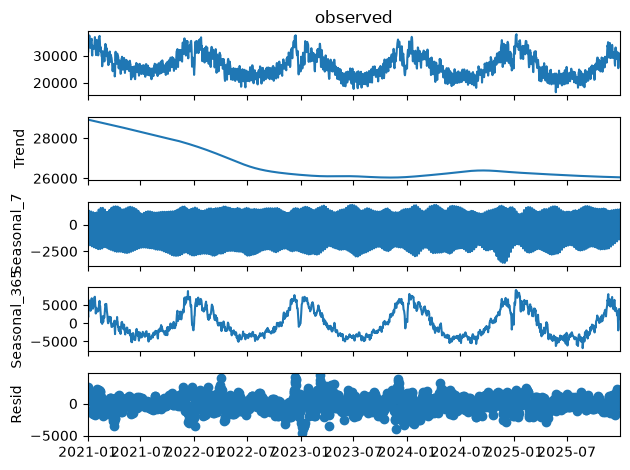

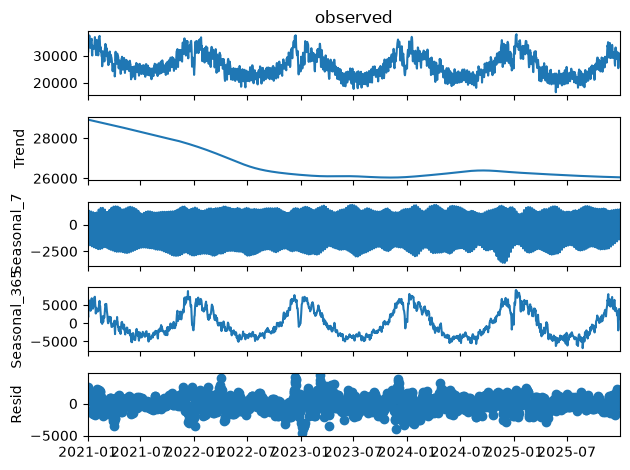

In [4]:
res = MSTL(y, periods=(7, 365)).fit()
res.plot()

In [5]:
# Exact size of each seasonal cycle (for findings 1 and 2)
for col in res.seasonal.columns:
    low, high = res.seasonal[col].min(), res.seasonal[col].max()
    print(f"{col}: {low:,.0f} to {high:,.0f} MW  (range {high - low:,.0f} MW)")

ratio = np.ptp(res.seasonal["seasonal_365"]) / np.ptp(res.seasonal["seasonal_7"])
print(f"Yearly cycle is {ratio:.1f}x the size of the weekly cycle")

seasonal_7: -3,573 to 1,831 MW  (range 5,405 MW)
seasonal_365: -6,855 to 9,073 MW  (range 15,928 MW)
Yearly cycle is 2.9x the size of the weekly cycle


In [6]:
for name, s in [("raw", y), ("diff 1", y.diff()), ("diff 7", y.diff(7))]:
    stat, p = adfuller(s.dropna())[:2]
    print(f"{name:7s}  ADF={stat:.2f}  p={p:.4f}")

raw      ADF=-3.31  p=0.0146
diff 1   ADF=-12.30  p=0.0000
diff 7   ADF=-10.05  p=0.0000


/var/folders/y6/r31lwc791xg6_2wmtm1htvm80000gn/T/ipykernel_88264/2812774349.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p = adfuller(s.dropna())[:2]
/var/folders/y6/r31lwc791xg6_2wmtm1htvm80000gn/T/ipykernel_88264/2812774349.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p = adfuller(s.dropna())[:2]
/var/folders/y6/r31lwc791xg6_2wmtm1htvm80000gn/T

date
2021     958.0
2022    1166.0
2023    1439.0
2024    1074.0
2025     948.0
Name: resid, dtype: float64


<Axes: title={'center': 'Daily demand, Apr–Sep 2025'}, xlabel='date'>

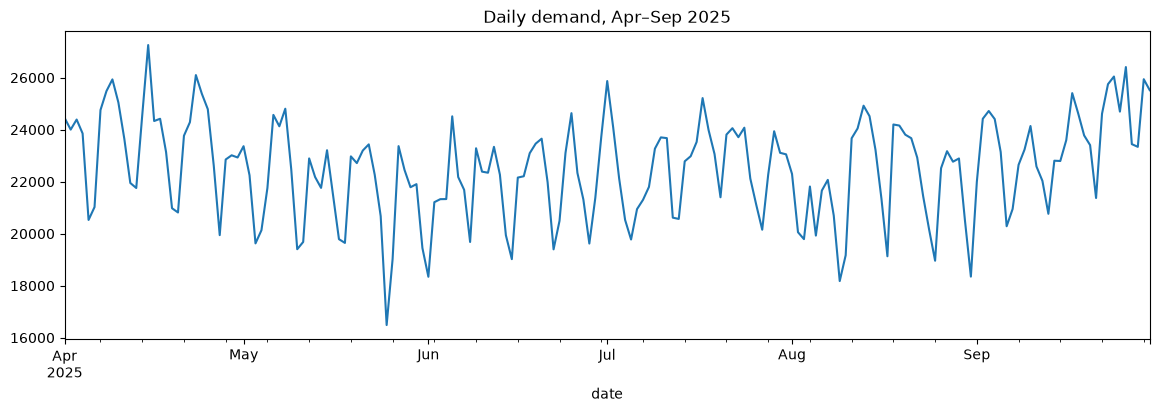

In [7]:
# 1. Has the noise really grown in 2025?
print(res.resid.groupby(res.resid.index.year).std().round(0))

# 2. What do summer 2025 daily values actually look like?
daily.loc["2025-04":"2025-09", "demand_mw"].plot(figsize=(14, 4), title="Daily demand, Apr–Sep 2025")

     mean_demand_mw  vs_weekday_avg_%
Mon         27778.0               0.2
Tue         27884.0               0.6
Wed         27892.0               0.6
Thu         27809.0               0.3
Fri         27202.0              -1.8
Sat         24680.0             -10.9
Sun         24260.0             -12.5

Weekend demand averages -11.7% vs the weekday average
Sunday vs weekday average: -12.5%


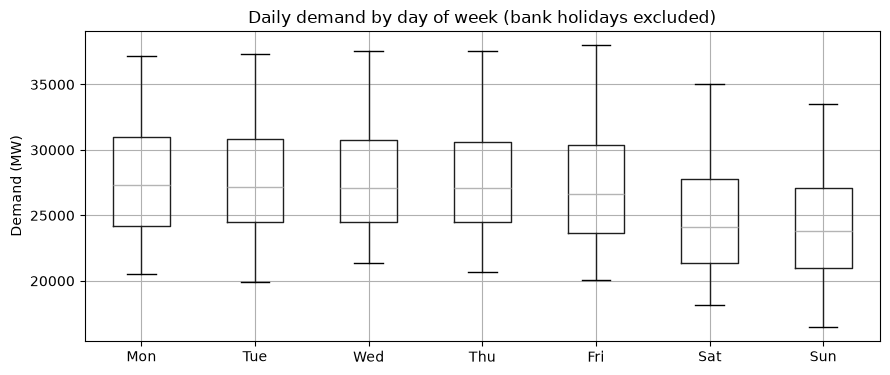

In [8]:
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
normal_days = daily[daily["is_holiday"] == 0]   # exclude bank holidays so they don't drag Mondays down

dow_mean = normal_days.groupby("day_of_week")["demand_mw"].mean()
dow_mean.index = dow_names
weekday_avg = dow_mean[:5].mean()
weekend_avg = dow_mean[5:].mean()

weekly = pd.DataFrame({
    "mean_demand_mw": dow_mean.round(0),
    "vs_weekday_avg_%": ((dow_mean / weekday_avg - 1) * 100).round(1),
})
print(weekly)
print(f"\nWeekend demand averages {weekend_avg / weekday_avg - 1:.1%} vs the weekday average")
print(f"Sunday vs weekday average: {dow_mean['Sun'] / weekday_avg - 1:.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
normal_days.boxplot(column="demand_mw", by="day_of_week", ax=ax)
ax.set_xticklabels(dow_names)
ax.set_title("Daily demand by day of week (bank holidays excluded)")
ax.set_xlabel("")
ax.set_ylabel("Demand (MW)")
fig.suptitle("")
plt.tight_layout()
plt.show()

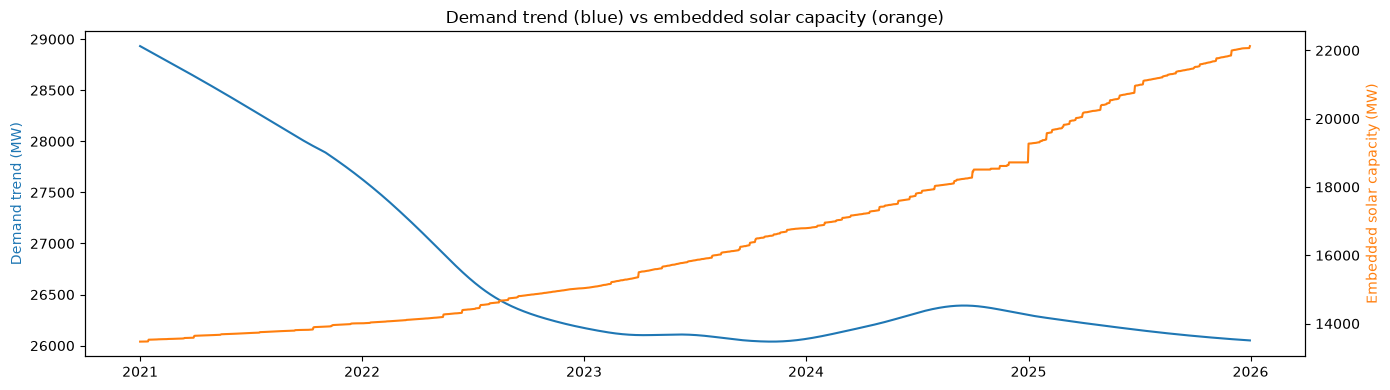

      mean_demand_mw  trend_mw  solar_capacity_mw  resid_std_mw
year                                                           
2021         28345.0   28309.0            13734.0         958.0
2022         26623.0   26745.0            14478.0        1166.0
2023         26052.0   26089.0            15889.0        1439.0
2024         26287.0   26271.0            17783.0        1074.0
2025         26158.0   26160.0            20813.0         948.0

Solar capacity 2021->2025: +52%
Demand trend   2021->2025: -7.6%
Correlation (daily trend vs solar capacity): -0.64


In [9]:
# Plot 1: demand trend vs embedded solar capacity on two y-axes
fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.plot(res.trend.index, res.trend, color="tab:blue")
ax1.set_ylabel("Demand trend (MW)", color="tab:blue")

ax2 = ax1.twinx()
ax2.plot(daily.index, daily["solar_capacity_mw"], color="tab:orange")
ax2.set_ylabel("Embedded solar capacity (MW)", color="tab:orange")

ax1.set_title("Demand trend (blue) vs embedded solar capacity (orange)")
fig.tight_layout()
plt.show()

# Table: one row per year
yearly = pd.DataFrame({
    "mean_demand_mw": daily["demand_mw"].groupby(daily.index.year).mean(),
    "trend_mw": res.trend.groupby(res.trend.index.year).mean(),
    "solar_capacity_mw": daily["solar_capacity_mw"].groupby(daily.index.year).mean(),
    "resid_std_mw": res.resid.groupby(res.resid.index.year).std(),
}).round(0)
yearly.index.name = "year"
print(yearly)

first, last = yearly.index.min(), yearly.index.max()
print(f"\nSolar capacity {first}->{last}: {yearly.loc[last, 'solar_capacity_mw'] / yearly.loc[first, 'solar_capacity_mw'] - 1:+.0%}")
print(f"Demand trend   {first}->{last}: {yearly.loc[last, 'trend_mw'] / yearly.loc[first, 'trend_mw'] - 1:+.1%}")
print(f"Correlation (daily trend vs solar capacity): {res.trend.corr(daily['solar_capacity_mw']):.2f}")

## Key findings

1. **Strong weekly cycle.** Excluding bank holidays, weekend demand averages **11.7% below** the weekday average, with Sunday the lowest at **12.5% below**. Weekdays are nearly flat; only Friday dips slightly (1.8%). In the MSTL decomposition the weekly component runs from **−3,573 to +1,831 MW** (range 5,405 MW). It's lopsided: weekends pull demand down further than weekdays push it up.

2. **The yearly cycle dominates.** The yearly component runs from **−6,855 to +9,073 MW** (range 15,928 MW), peaking each winter. That's **2.9× the size of the weekly cycle**, so the yearly pattern matters most.

3. **Bank holidays behave like weekends.** Bank holidays average **15.3% below** normal weekdays in the same month, an even bigger dip than an ordinary weekend. This justifies `is_holiday` as a model feature.

4. **Demand fell, then levelled off.** The trend averaged **28,309 MW in 2021** and **26,089 MW in 2023**, a drop of about 8%, most of it during 2022. Since then it has stayed within about 1% (26,271 MW in 2024, 26,160 MW in 2025): **−7.6% overall from 2021 to 2025**. Over the same period, embedded solar capacity grew **52%** (13,734 → 20,813 MW), and the two series are negatively correlated (r = −0.64). The fall is *consistent with* both the 2022 energy-price crisis and growing behind-the-meter solar. Two steadily changing series will always correlate strongly, and with five years of data neither cause can be confirmed.

5. **Calendar patterns explain demand well, except in 2022–2023.** After removing trend and seasonality, residual noise was **958 MW in 2021**, peaked at **1,439 MW in 2023**, and fell back to **948 MW in 2025**. So demand isn't steadily getting harder to predict; 2025 is the most regular year in the data. The 2022–2023 bump coincides with the energy-price crisis, when demand behaviour shifted, which is consistent with but not proof of a link. Weather (temperature, solar irradiance) remains the most likely source of the variation that calendar features can't explain.

6. **No regular differencing needed, but the evidence is moderate.** ADF on the raw series: statistic −3.31, **p = 0.015**. That rejects a unit root at the 5% level, though not at 1%. The first- and weekly-differenced series are clearly stationary (p < 0.001). ADF doesn't test for seasonality, so the weekly and yearly cycles still have to be modelled explicitly.

7. **Prediction for the model comparison.** SARIMA supports only one seasonal period. With period 7 it captures the weekly cycle but not the yearly one, which is 2.9× larger. Prophet models weekly and yearly seasonality together. **Expected outcome: Prophet should beat SARIMA, especially at longer horizons.** The baseline results will test this.

### Data-quality note
The 2025 source file uses ISO dates (`YYYY-MM-DD`), unlike earlier years. A flexible parser with day-first enabled swapped day and month for days 1–12 of every month in 2025, putting winter demand into summer. Row counts and gap checks all passed, because a swap loses nothing; the error showed up as regular winter-level spikes in summer 2025. It was fixed with explicit per-format parsing plus a check that dates never go backwards within each file.